In [106]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch.nn as nn
from torch.utils.data import DataLoader,Dataset
import torch.optim as optim
import matplotlib.pyplot as plt
import torch

In [107]:
torch.manual_seed(42)

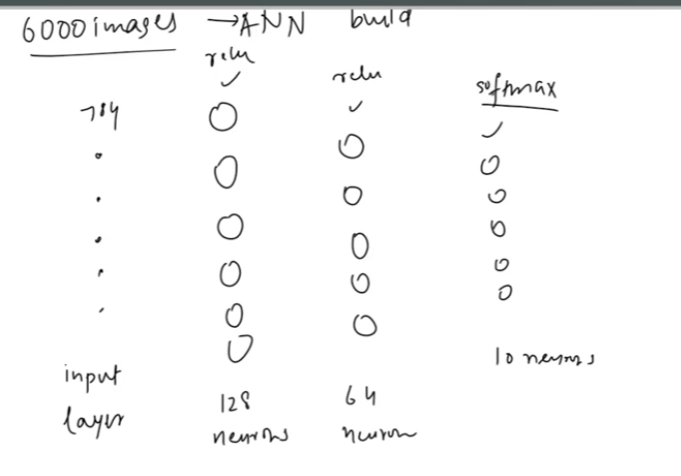

In [108]:
df = pd.read_csv('fmnist_small.csv')

In [109]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,pixel15,pixel16,pixel17,pixel18,pixel19,pixel20,pixel21,pixel22,pixel23,pixel24,pixel25,pixel26,pixel27,pixel28,pixel29,pixel30,pixel31,pixel32,pixel33,pixel34,pixel35,pixel36,pixel37,pixel38,pixel39,...,pixel745,pixel746,pixel747,pixel748,pixel749,pixel750,pixel751,pixel752,pixel753,pixel754,pixel755,pixel756,pixel757,pixel758,pixel759,pixel760,pixel761,pixel762,pixel763,pixel764,pixel765,pixel766,pixel767,pixel768,pixel769,pixel770,pixel771,pixel772,pixel773,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,125,72,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,3,0,2,0,0,210,228,228,233,0,0,0,0,0,0,0,0,0,31,81,133,184,201,190,117,0,0,2,1,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,43,117,34,15,24,33,117,80,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,51,144,152,...,157,158,161,148,159,58,0,6,0,0,0,0,0,0,0,0,0,4,0,60,143,143,148,146,152,152,148,148,147,145,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,0,0,0,2,0,33,114,37,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...,11,17,13,13,11,10,7,5,5,5,7,0,0,0,1,0,0,41,69,88,86,94,106,114,118,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,0,2,0,58,145,114,10,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,...,165,153,155,134,143,172,215,62,0,0,0,0,0,0,0,0,10,190,178,194,209,211,209,205,211,215,213,217,225,228,213,203,174,151,188,10,0,0,0,0


In [110]:
df.shape

(6000, 785)

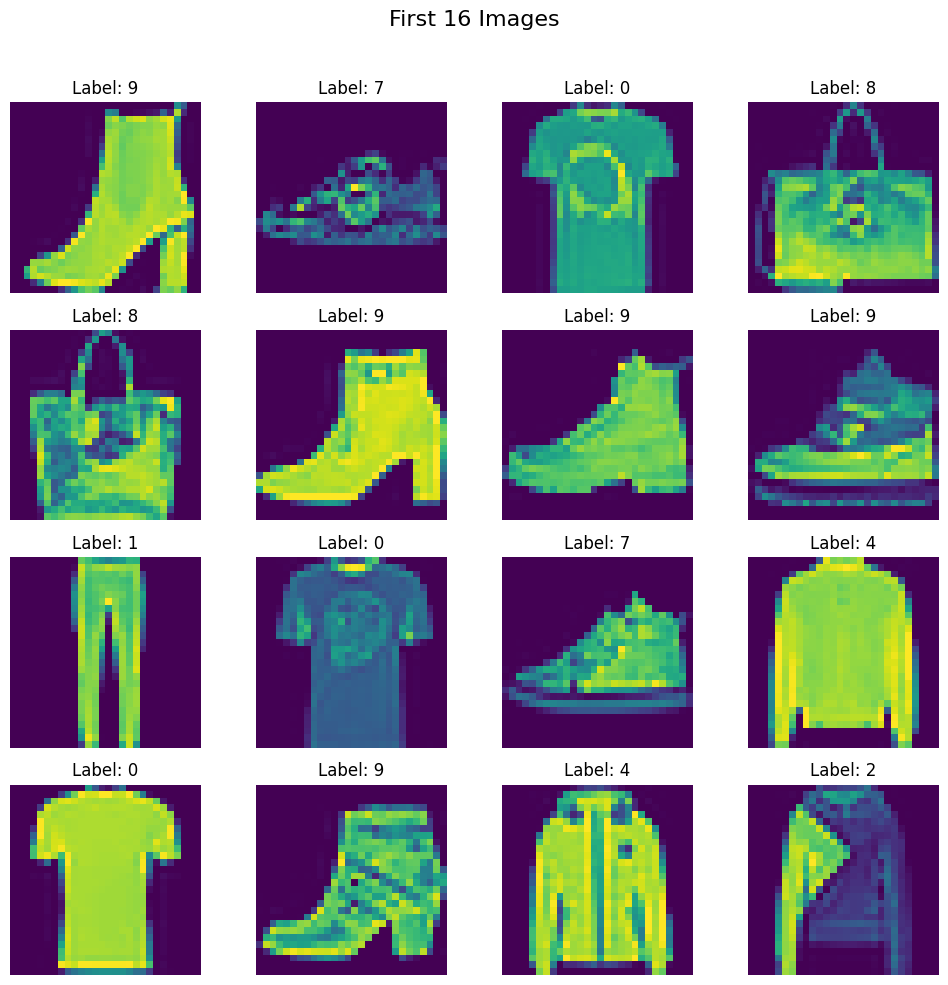

In [111]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()


In [112]:
x = df.iloc[:,1:].values
y = df.iloc[:,0:1].values

In [113]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [114]:
x_train.shape

(4800, 784)

In [115]:
# feature scalling
x_train = x_train/255.0
x_test = x_test/255.0

# The Class Declaration: class customDataset(Dataset):

• What it does: This defines your new dataset type.
• The parent (Dataset): This tells Python that your class inherits from PyTorch's built-in Dataset utility. By doing this, your custom dataset automatically becomes compatible with PyTorch's DataLoader (which handles shuffling, batching, and multiprocessing for your model).


# 1. The Initialization Function: __init__(self, features, leables):

• Purpose: This function runs automatically the exact moment you create your dataset (e.g., when you write dataset = customDataset(X, y)). It acts as the setup manager.
• self.features = torch.tensor(...): It takes your raw input data (like images, text arrays, or numbers) and converts them into a PyTorch Float32 Tensor so the neural network can run math calculations on it.
• self.leables = torch.tensor(...): It takes your target answers (labels) and converts them into a PyTorch Long Tensor (integers). This is the standard data type PyTorch expects for classification categories.

# 2. The Length Function: __len__(self):

• Purpose: This tells PyTorch exactly how many items are inside your dataset.

# 3. The Item Retrieval Function: __getitem__(self, index):

• Purpose: This allows you to pull out a single data point and its matching label using an index number (e.g., dataset[5]).

In [116]:
# create a customDataset class
class customDataset(Dataset):
  def __init__(self, features, leables):
    self.features = torch.tensor(features, dtype = torch.float32)
    self.leables = torch.tensor(leables, dtype = torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index], self.leables[index]

In [117]:
# create train dataset
train_dataset = customDataset(x_train, y_train)

In [118]:
# create test dataset
test_dataset = customDataset(x_test, y_test)

In [119]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [120]:
train_dataset[0]

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0

In [121]:
# define NN class

class MyNN(nn.Module):

  def __init__(self, num_features):

    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )

  def forward(self, x):

    return self.model(x)

In [122]:
# set learning rate and epochs
epochs = 100
learning_rate = 0.1

In [123]:
# instanciate the class
model = MyNN(x_train.shape[1])

# Loss function
loss_function = nn.CrossEntropyLoss()

# optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [124]:
# treaning loop

for epoch in range(epochs):

  total_epochs_loss = 0

  for batch_features, batch_leable in train_loader:

    # forword pass
    outputs = model(batch_features)

    # calculate loss
    loss = loss_function(outputs, batch_leable.flatten())

    # backpropogation
    optimizer.zero_grad()
    loss.backward()

    # update parameters
    optimizer.step()

    total_epochs_loss += loss.item()

  avg_loss = total_epochs_loss / len(train_loader)
  print(f'epoch : {epoch+1} , Loss : {avg_loss}')

epoch : 1 , Loss : 1.3216368528207143
epoch : 2 , Loss : 0.7793365389108657
epoch : 3 , Loss : 0.6427524648110072
epoch : 4 , Loss : 0.5751657428344091
epoch : 5 , Loss : 0.5281802035371462
epoch : 6 , Loss : 0.49528750280539197
epoch : 7 , Loss : 0.4602432996034622
epoch : 8 , Loss : 0.435945917169253
epoch : 9 , Loss : 0.41829213748375577
epoch : 10 , Loss : 0.39840924287835755
epoch : 11 , Loss : 0.3850264524420102
epoch : 12 , Loss : 0.37226856033007305
epoch : 13 , Loss : 0.34775472511847816
epoch : 14 , Loss : 0.34747447177767754
epoch : 15 , Loss : 0.31615055337548253
epoch : 16 , Loss : 0.31182024608055753
epoch : 17 , Loss : 0.2919234921534856
epoch : 18 , Loss : 0.2852401979267597
epoch : 19 , Loss : 0.2716610049704711
epoch : 20 , Loss : 0.2620930323501428
epoch : 21 , Loss : 0.2573009904225667
epoch : 22 , Loss : 0.2422846657037735
epoch : 23 , Loss : 0.2393271365016699
epoch : 24 , Loss : 0.22775985998411974
epoch : 25 , Loss : 0.224474375123779
epoch : 26 , Loss : 0.21341

In [125]:
# evulation code
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [128]:
# evaluation code
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels.flatten()).sum().item()

print(correct/total)

0.8291666666666667


In [127]:
len(test_loader)

38